

## Датасет
- Источник: Schneider-Electric
- Формат: CSV с разделителем `;`
- Столбцы: `Timestamp`, `SensorId`, `Value`
- Период: несколько месяцев измерений

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy.ndimage import label

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используется устройство: {device}")

plt.style.use('seaborn-v0_8-darkgrid')

Используется устройство: cuda


## Загрузка и подготовка данных

На этом этапе:
- Загружаем CSV файл с разделителем `;`
- Фильтруем данные только для датчика PT100 (SensorId = 1)
- Преобразуем временные метки и сортируем по времени
- Заполняем пропуски методом линейной интерполяции
- Разделяем данные на train/test ДО масштабирования, чтобы избежать утечки данных

In [3]:
# Загрузка данных
print("Загрузка данных...")
df = pd.read_csv('sensor-fault-detection.csv', sep=';')

# Фильтрация для датчика PT100
if 'SensorId' in df.columns:
    df = df[df['SensorId'] == 1].copy()
    print(f"Отфильтровано записей для SensorId == 1: {len(df)}")

# Преобразование времени и сортировка
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df = df.sort_values('Timestamp').reset_index(drop=True)

# Заполнение пропусков
df['Value'] = df['Value'].interpolate(method='linear').ffill().bfill()

# Разделение на train/test (80/20) до масштабирования
train_size_raw = int(0.8 * len(df))
df_train = df.iloc[:train_size_raw].copy()
df_test = df.iloc[train_size_raw:].copy()

print(f"Тренировочная выборка: {len(df_train)} записей")
print(f"Тестовая выборка: {len(df_test)} записей")

# Масштабирование на тренировочных данных
scaler = StandardScaler()
train_scaled = scaler.fit_transform(df_train[['Value']])
test_scaled = scaler.transform(df_test[['Value']])

# Создание скользящих окон
SEQ_LEN = 30  # Длина окна в минутах/замерах

def create_sequences(data, seq_length):
    """Создает последовательности для LSTM"""
    return np.array([data[i:(i + seq_length)] for i in range(len(data) - seq_length)])

X_train = create_sequences(train_scaled, SEQ_LEN)
X_test = create_sequences(test_scaled, SEQ_LEN)

print(f"Форма X_train: {X_train.shape}")
print(f"Форма X_test: {X_test.shape}")

Загрузка данных...
Отфильтровано записей для SensorId == 1: 62629
Тренировочная выборка: 50103 записей
Тестовая выборка: 12526 записей
Форма X_train: (50073, 30, 1)
Форма X_test: (12496, 30, 1)


## Архитектура модели: Denoising LSTM Autoencoder

Модель состоит из двух частей:
- **Энкодер**: LSTM, который сжимает входную последовательность в скрытое состояние
- **Декодер**: LSTM, который восстанавливает последовательность из скрытого состояния

**Denoising подход**: Во время обучения мы добавляем гауссовский шум к входным данным. Это заставляет модель учиться выделять полезный сигнал и игнорировать шум, что делает её более устойчивой к аномалиям.

In [4]:
class DenoisingLSTMAutoencoder(nn.Module):
    """Denoising LSTM Autoencoder для обнаружения аномалий"""

    def __init__(self, seq_len, n_features, embedding_dim=32):
        super().__init__()
        self.seq_len = seq_len
        self.n_features = n_features

        # Энкодер: сжимает входную последовательность
        self.encoder = nn.LSTM(
            input_size=n_features,
            hidden_size=embedding_dim,
            num_layers=1,
            batch_first=True
        )

        # Декодер: восстанавливает последовательность
        self.decoder = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=n_features,
            num_layers=1,
            batch_first=True
        )

        self.output_layer = nn.Linear(n_features, n_features)

    def forward(self, x):
        # x: (batch, seq_len, n_features)
        _, (hidden, cell) = self.encoder(x)

        # Повторяем скрытое состояние для каждого шага времени
        decoder_input = hidden.repeat(self.seq_len, 1, 1).permute(1, 0, 2)

        # Декодирование
        decoder_out, _ = self.decoder(decoder_input)

        return self.output_layer(decoder_out)

# Инициализация модели
model = DenoisingLSTMAutoencoder(seq_len=SEQ_LEN, n_features=1).to(device)
print(f"Модель инициализирована на устройстве: {device}")
print(f"Количество параметров: {sum(p.numel() for p in model.parameters()):,}")

Модель инициализирована на устройстве: cuda
Количество параметров: 4,622


## Итеративное обучение с очисткой данных

**Проблема**: В тренировочных данных могут присутствовать аномалии (сбои датчика), которые искажают обучение модели.

**Решение**: Двухэтапное обучение:
1. **Первый этап**: Обучаем модель на всех данных и вычисляем ошибки реконструкции
2. **Очистка**: Удаляем окна с высокой ошибкой (аномалии) из тренировочного набора
3. **Второй этап**: Переобучаем модель только на "чистых" данных

Это делает модель более устойчивой и точной.

In [5]:
def train_and_clean(X_data, epochs=15, batch_size=128, lr=1e-3, noise_level=0.1):
    """
    Обучает модель и удаляет аномальные окна из тренировочного набора

    Args:
        X_data: Входные данные (окна)
        epochs: Количество эпох обучения
        batch_size: Размер батча
        lr: Скорость обучения
        noise_level: Уровень шума для denoising подхода

    Returns:
        model: Обученная модель
        X_clean: Очищенные данные (без аномалий)
        threshold: Порог аномалии
    """
    model = DenoisingLSTMAutoencoder(seq_len=SEQ_LEN, n_features=1).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_loader = DataLoader(
        TensorDataset(torch.FloatTensor(X_data)),
        batch_size=batch_size,
        shuffle=True
    )

    # Обучение модели
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for batch in train_loader:
            batch_x = batch[0].to(device)

            # Добавляем шум (denoising подход)
            noise = torch.randn_like(batch_x) * noise_level
            noisy_input = batch_x + noise

            # Прямой проход, вычисление ошибки, обратный проход
            optimizer.zero_grad()
            output = model(noisy_input)
            loss = criterion(output, batch_x)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        print(f'  Epoch {epoch+1}/{epochs}, Loss: {epoch_loss/len(train_loader):.6f}')

    # Вычисление ошибок реконструкции для очистки
    model.eval()
    errors = []
    with torch.no_grad():
        for batch in train_loader:
            batch_x = batch[0].to(device)
            output = model(batch_x)
            loss = torch.mean((output - batch_x) ** 2, dim=[1, 2])
            errors.extend(loss.cpu().numpy())
    errors = np.array(errors)

    # Робастный порог: медиана + 3 * MAD (Median Absolute Deviation)
    median_error = np.median(errors)
    mad = np.median(np.abs(errors - median_error))
    threshold = median_error + 3 * 1.4826 * mad  # 1.4826 - константа для нормального распределения

    # Удаляем аномальные окна
    clean_mask = errors <= threshold
    X_clean = X_data[clean_mask]

    print(f'  -> Удалено аномальных окон: {np.sum(~clean_mask)} из {len(errors)}')
    print(f'  -> Осталось чистых окон: {np.sum(clean_mask)}')
    print(f'  -> Порог аномалии: {threshold:.6f}')

    return model, X_clean, threshold

# Этап 1: Начальное обучение на всех данных
print("\n[Этап 1] Начальное обучение на всех данных...")
model, X_train_clean, threshold = train_and_clean(X_train, epochs=15)

# Этап 2: Переобучение на очищенных данных
print("\n[Этап 2] Переобучение на очищенных данных...")
model, X_train_clean, threshold = train_and_clean(X_train_clean, epochs=10)


[Этап 1] Начальное обучение на всех данных...
  Epoch 1/15, Loss: 0.800582
  Epoch 2/15, Loss: 0.559131
  Epoch 3/15, Loss: 0.301803
  Epoch 4/15, Loss: 0.232871
  Epoch 5/15, Loss: 0.161472
  Epoch 6/15, Loss: 0.129640
  Epoch 7/15, Loss: 0.110923
  Epoch 8/15, Loss: 0.107676
  Epoch 9/15, Loss: 0.089685
  Epoch 10/15, Loss: 0.083443
  Epoch 11/15, Loss: 0.079138
  Epoch 12/15, Loss: 0.076447
  Epoch 13/15, Loss: 0.083379
  Epoch 14/15, Loss: 0.073342
  Epoch 15/15, Loss: 0.072476
  -> Удалено аномальных окон: 8705 из 50073
  -> Осталось чистых окон: 41368
  -> Порог аномалии: 0.006397

[Этап 2] Переобучение на очищенных данных...
  Epoch 1/10, Loss: 0.385195
  Epoch 2/10, Loss: 0.153520
  Epoch 3/10, Loss: 0.116494
  Epoch 4/10, Loss: 0.099714
  Epoch 5/10, Loss: 0.090160
  Epoch 6/10, Loss: 0.084197
  Epoch 7/10, Loss: 0.080255
  Epoch 8/10, Loss: 0.077692
  Epoch 9/10, Loss: 0.079028
  Epoch 10/10, Loss: 0.074755
  -> Удалено аномальных окон: 7790 из 41368
  -> Осталось чистых око

## Оценка на тестовой выборке и группировка событий

После обучения:
- Вычисляем ошибку реконструкции для каждого окна в тестовой выборке
- Применяем порог, полученный на этапе очистки
- **Группируем соседние аномальные окна в логические события** (если датчик сбоил 10 минут подряд — это одно событие, а не 10 отдельных)

In [6]:
print("\n[Этап 3] Оценка на тестовой выборке...")

model.eval()
test_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_test)),
    batch_size=128,
    shuffle=False
)

# Вычисление ошибок реконструкции
test_errors = []
with torch.no_grad():
    for batch in test_loader:
        batch_x = batch[0].to(device)
        output = model(batch_x)
        loss = torch.mean((output - batch_x) ** 2, dim=[1, 2])
        test_errors.extend(loss.cpu().numpy())
test_errors = np.array(test_errors)

# Определение аномалий по порогу
anomaly_labels = (test_errors > threshold).astype(int)

print(f"Всего проверено окон: {len(anomaly_labels)}")
print(f"Аномальных окон: {anomaly_labels.sum()} ({100 * anomaly_labels.sum() / len(anomaly_labels):.2f}%)")

# Группировка соседних аномалий в события
labeled_array, num_events = label(anomaly_labels)
print(f'\n найдено событий (кластеров аномалий): {num_events}')

# Детальная информация о каждом событии
events = []
for i in range(1, num_events + 1):
    idx = np.where(labeled_array == i)[0]
    events.append({
        'start_idx': idx[0],
        'end_idx': idx[-1],
        'duration_windows': len(idx),
        'max_error': test_errors[idx].max(),
        'start_time': df_test['Timestamp'].iloc[SEQ_LEN + idx[0]],
        'end_time': df_test['Timestamp'].iloc[SEQ_LEN + idx[-1]]
    })

# Вывод первых 10 событий
print(f'\nПервые 10 событий:')
for idx, event in enumerate(events[:10]):
    print(f"  Событие {idx+1}: {event['start_time']} - {event['end_time']} "
          f"(длительность: {event['duration_windows']} окон, макс. ошибка: {event['max_error']:.4f})")


[Этап 3] Оценка на тестовой выборке...
Всего проверено окон: 12496
Аномальных окон: 578 (4.63%)

 найдено событий (кластеров аномалий): 29

Первые 10 событий:
  Событие 1: 2017-07-21 13:50:00+03:00 - 2017-07-21 15:30:00+03:00 (длительность: 21 окон, макс. ошибка: 0.0113)
  Событие 2: 2017-07-24 13:05:00+03:00 - 2017-07-24 14:00:00+03:00 (длительность: 12 окон, макс. ошибка: 0.0081)
  Событие 3: 2017-07-25 08:10:00+03:00 - 2017-07-25 09:25:00+03:00 (длительность: 16 окон, макс. ошибка: 0.0102)
  Событие 4: 2017-07-29 08:00:00+03:00 - 2017-07-29 08:50:00+03:00 (длительность: 11 окон, макс. ошибка: 0.0073)
  Событие 5: 2017-07-29 12:30:00+03:00 - 2017-07-29 13:50:00+03:00 (длительность: 17 окон, макс. ошибка: 0.0087)
  Событие 6: 2017-08-01 05:55:00+03:00 - 2017-08-01 07:50:00+03:00 (длительность: 24 окон, макс. ошибка: 0.0116)
  Событие 7: 2017-08-02 12:25:00+03:00 - 2017-08-02 13:25:00+03:00 (длительность: 13 окон, макс. ошибка: 0.0075)
  Событие 8: 2017-08-07 06:45:00+03:00 - 2017-08-

## Визуализация результатов

Строим два графика:
1. **Верхний**: Исходный сигнал датчика с подсвеченными областями аномалий
2. **Нижний**: Ошибка реконструкции модели во времени с пороговым значением

Это позволяет визуально оценить качество обнаружения аномалий.

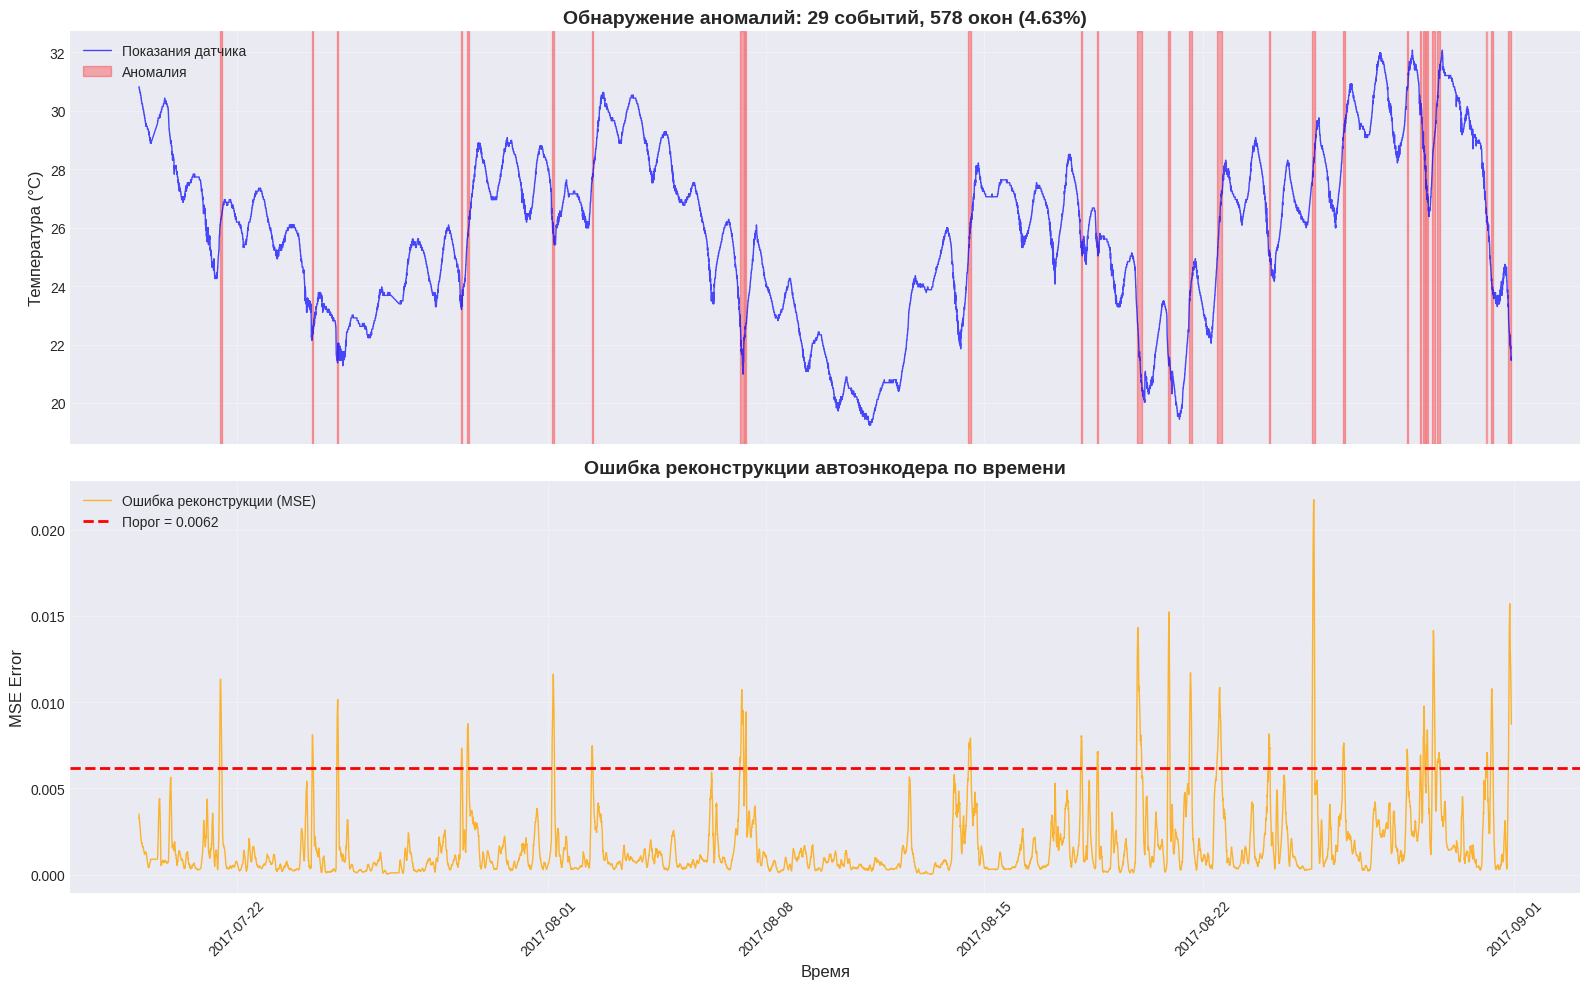


 Статистика:
  Обнаружено 578 аномальных окон (4.63%)
  Сгруппировано в 29 событий
  Средняя длительность события: 19.9 окон
  Максимальная ошибка: 0.0217


In [8]:
# Подготовка данных для визуализации
test_end_indices = np.arange(SEQ_LEN, SEQ_LEN + len(X_test))
test_timestamps = df_test['Timestamp'].iloc[test_end_indices].values
test_values = df_test['Value'].iloc[test_end_indices].values

# Создание графиков
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# График 1: Исходный сигнал и аномалии
ax1.plot(test_timestamps, test_values, label='Показания датчика', color='blue', alpha=0.7, linewidth=1)

# Подсвечиваем области аномалий
for event in events:
    ax1.axvspan(event['start_time'], event['end_time'],
                color='red', alpha=0.3,
                label='Аномалия' if event == events[0] else '')

ax1.set_title(f'Обнаружение аномалий: {num_events} событий, {anomaly_labels.sum()} окон ({100*anomaly_labels.sum()/len(anomaly_labels):.2f}%)',
              fontsize=14, fontweight='bold')
ax1.set_ylabel('Температура (°C)', fontsize=12)
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# График 2: Ошибка реконструкции
ax2.plot(test_timestamps, test_errors, label='Ошибка реконструкции (MSE)', color='orange', alpha=0.8, linewidth=1)
ax2.axhline(threshold, color='red', linestyle='--', linewidth=2, label=f'Порог = {threshold:.4f}')
ax2.set_title('Ошибка реконструкции автоэнкодера по времени', fontsize=14, fontweight='bold')
ax2.set_xlabel('Время', fontsize=12)
ax2.set_ylabel('MSE Error', fontsize=12)
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"\n Статистика:")
print(f"  Обнаружено {anomaly_labels.sum()} аномальных окон ({100 * anomaly_labels.sum() / len(anomaly_labels):.2f}%)")
print(f"  Сгруппировано в {num_events} событий")
if events:
    print(f"  Средняя длительность события: {np.mean([e['duration_windows'] for e in events]):.1f} окон")
    print(f"  Максимальная ошибка: {max(e['max_error'] for e in events):.4f}")

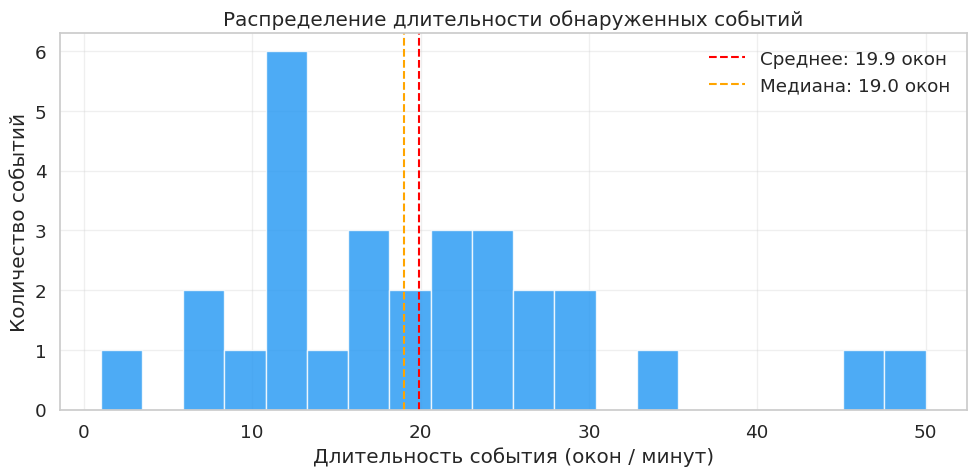

Медиана длительности: 19.0 окон
Событий короче 5 окон: 1
Событий длиннее 50 окон: 0


In [11]:
plt.figure(figsize=(10, 5))
durations = [e['duration_windows'] for e in events]
plt.hist(durations, bins=20, color='#2196F3', edgecolor='white', alpha=0.8)
plt.axvline(np.mean(durations), color='red', linestyle='--',
            label=f'Среднее: {np.mean(durations):.1f} окон')
plt.axvline(np.median(durations), color='orange', linestyle='--',
            label=f'Медиана: {np.median(durations):.1f} окон')
plt.xlabel('Длительность события (окон / минут)')
plt.ylabel('Количество событий')
plt.title('Распределение длительности обнаруженных событий')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Медиана длительности: {np.median(durations):.1f} окон")
print(f"Событий короче 5 окон: {sum(1 for d in durations if d < 5)}")
print(f"Событий длиннее 50 окон: {sum(1 for d in durations if d > 50)}")

In [12]:
# Точка считается аномальной, если хотя бы одно окно, её содержащее, — аномалия
full_labels = np.zeros(len(df), dtype=int)
for i, label in enumerate(anomaly_labels):
    if label == 1:
        full_labels[SEQ_LEN + i : SEQ_LEN + i + SEQ_LEN] = 1

# full_labels — итоговый массив той же длины, что и входные данные
print(f"Итоговый массив меток (длина = {len(full_labels)}):")
print(full_labels)

Итоговый массив меток (длина = 62629):
[0 0 0 ... 0 0 0]


### **В ходе выполнения лабораторной работы была успешно решена задача обнаружения аномалий в телеметрических данных промышленного датчика PT100 методом обучения без учителя.**

Для решения задачи была разработана и обучена архитектура Denoising LSTM Autoencoder. Применение подхода с искусственным зашумлением входных данных (denoising) и двухэтапной итеративной очисткой тренировочной выборки позволило модели научиться реконструировать нормальный сигнал, игнорируя шум и редкие выбросы. Порог аномальности определялся робастным статистическим методом (медиана + 3×MAD), что обеспечило устойчивость модели к наличию скрытых сбоев в обучающих данных и предотвратило утечку данных (data leakage).

# **Результаты:**

*   На тестовой выборке обнаружено 578 аномальных окон, что составляет 4.63% от общего объема данных
*   Аномальные окна сгруппированы в 29 логических событий (инцидентов).
*  Средняя длительность события составила ~20 минут, а распределение длительностей оказалось симметричным, что свидетельствует об отсутствии массовых ложных срабатываний на кратковременный шум.
*  Максимальная ошибка реконструкции в пиках превышала пороговое значение в 3.5 раза, подтверждая высокую уверенность модели при детектировании явных сбоев.


